# Bước A4 - huấn luyện lại Sequential Forecast LSTM có Q của BiasCast với 3 hạt giống (111, 222, 333) trên Kaggle T4 để đo nhiễu giữa hạt giống
 Bài: Konold và cs., HESS 30:5067-5096 (2026). Dữ liệu Zenodo 17119635 (CC BY-NC 4.0), config tác giả Zenodo 17292895
      - đã lưu thành Kaggle Dataset "lamah-ce-ext" (Workspace/01_Download/01_LamaHCEExt_Download.py).
 Kế hoạch: Document/01_Plan/03_Pipeline.md Mục 7 (dòng A4), 8.1 (ngân sách thời gian), 9.5 (định dạng dự báo).
 Mỗi hạt giống một tệp và một notebook Kaggle cùng tên: "03_A4_LamaHCEExt_Retrain_Seed111", "..._Seed222",
 "..._Seed333" - ba tệp giống hệt nhau, chỉ khác dòng RUN_SEED ở Phần 1. Một lần huấn luyện + đánh giá mất 1,2-4,7 giờ
 trên T4 (đo 24/10/2026); hai lần song song trên 2 GPU chậm 1,45 lần vì tranh 4 CPU, ba lần tuần tự có thể vượt 12 giờ,
 nên tách. So sánh 3 hạt giống với tác giả ở notebook CPU "04_A4_LamaHCEExt_Compare".
 Cài đặt mỗi notebook: Accelerator = GPU T4 x2 (dùng 1), Internet = On, Persistence = Files only,
 Environment = Pin to original environment, Add Input => lamah-ce-ext. Mỗi Phần dán vào 1 cell, chạy lần lượt.
 Dán nguyên tệp vào notebook rồi Save & Run All, không sửa dòng nào; Output chính thức (a4_runs/, a4_output/) lấy
 từ bản lưu đó.

# MỤC LỤC
   Phần 1 - Cài thư viện NeuralHydrology từ fork của nhóm, kiểm môi trường, 2 GPU, tensorboard
   Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
   Phần 3 - Dựng thư mục dữ liệu có cột qmean
   Phần 4 - Tạo config cho hạt giống RUN_SEED
   Phần 5 - Huấn luyện hạt giống RUN_SEED
   Phần 6 - Đánh giá test và validation, xác định epoch của best_model.pt
   Phần 7 - Ghi môi trường, danh mục tệp, dọn thư mục dữ liệu tạm

Thư viện,Phiên bản,pip đổi?
neuralhydrology,1.12.0 (commit dda45fc),
numpy,2.1.3,
pandas,2.3.3,
xarray,2025.12.0,
torch,2.11.0+cu128,
scipy,1.16.3,
numba,0.61.2,
ruamel.yaml,0.19.1,
matplotlib,3.10.0,
tensorboard,2.20.0,


Mục,Giá trị
Python,3.13.15
torch / CUDA của torch,2.11.0+cu128 / 12.8
cuDNN,91900
Số GPU,2
GPU,"0: Tesla T4 (cc 7.5, 14.6 GB); 1: Tesla T4 (cc 7.5, 14.6 GB)"
Số CPU,4
RAM tổng / còn trống (GB),31.3 / 29.7
Đĩa trống ở WORK_DIR (GB),19.5
Ngày dựng ảnh Kaggle,20261022-041805


Điều kiện,Đạt
Cài đúng commit dda45fc,ĐẠT
pip không đổi thư viện có sẵn,ĐẠT
Có 2 GPU T4,ĐẠT
Có tensorboard,ĐẠT
Nạp nh_run,ĐẠT
Nạp logger,ĐẠT
Nạp sequential_forecast_lstm,ĐẠT


=> Đạt. Chạy Phần 2.


mục,đường dẫn,ghi chú
Dữ liệu,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/lamah_ce_ext/LamaH_extended,
Kết quả tác giả,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/biascast_experiments/Experiments,
Danh sách lưu vực,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/biascast_experiments/Experiments/basins_filtered.txt,"451 lưu vực, 451 mã khác nhau"
Run tác giả: config,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/config.yml,có
Run tác giả: best_model.pt,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/best_model.pt,có
Run tác giả: scaler,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/train_data/train_data_scaler.yml,có
Run tác giả: test_metrics,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/test/best_model/test_metrics.csv,có


...

Thư mục run: /kaggle/working/a4_runs/A4_SeqLSTM_Q_seed222_2310_194052
=> Đạt. Chạy Phần 6.


epoch,NSE trung vị validation (tệp),số lưu vực,lưu vực có NSE,NSE trung vị validation (log),khớp log,ghi chú
1,0.626490,451,450,0.626490,True,
2,0.667170,451,450,0.667170,True,
3,0.691940,451,450,0.691940,True,
4,0.725230,451,450,0.725230,True,
5,0.720140,451,450,0.720140,True,
6,0.729620,451,450,0.729620,True,
7,0.737270,451,450,0.737270,True,
8,0.727920,451,450,0.727920,True,
9,0.738220,451,450,0.738220,True,
10,0.729100,451,450,0.729100,True,


Basin 55 All simulated values are NaN, thus metrics will be NaN, too.


Đánh giá test best_model: 5.3 phút


mô hình,NSE trung vị validation,NSE trung vị test,KGE trung vị test,lưu vực có NSE test,Δ NSE test so với tác giả
best_model.pt (epoch 15),0.754140,0.703780,0.790980,450,-0.001510
"tác giả (best_model.pt, Zenodo)",nan,0.705280,0.767070,450,0.000000


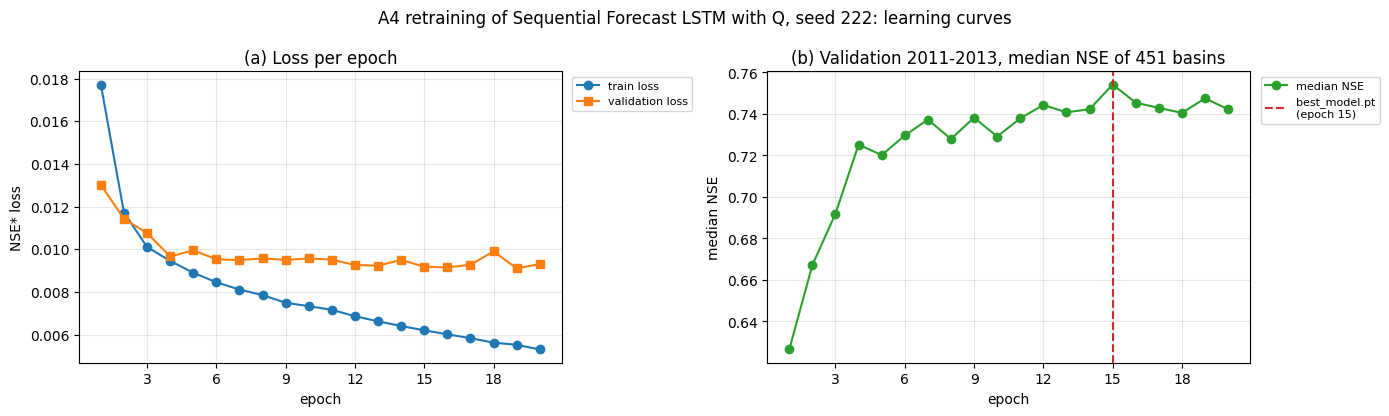

Hình: đường học của hạt giống 222. (a) loss NSE* trung bình theo epoch của kỳ huấn luyện và kỳ validation - loss huấn luyện giảm còn loss validation tăng là dấu hiệu quá khớp. (b) NSE trung vị validation theo epoch; vạch đỏ là epoch được lưu thành best_model.pt, vạch cam (nếu có) là epoch NSE cao nhất thật - hai vạch khác nhau nghĩa là best_model.pt không phải epoch tốt nhất (thư viện chỉ dời mốc khi NSE tăng quá 0,005).


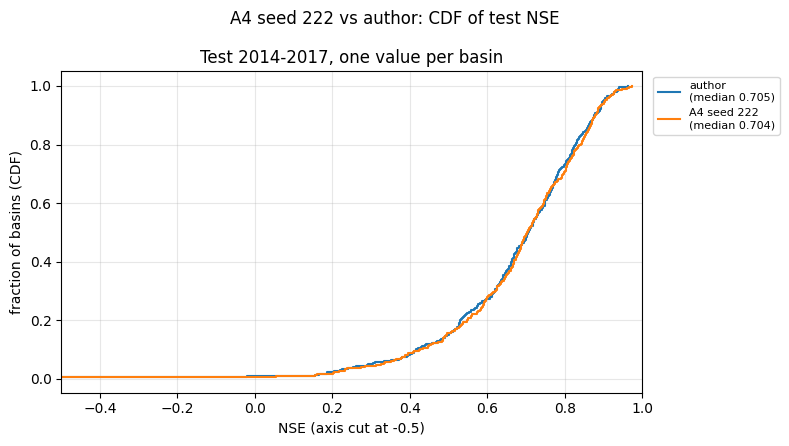

Hình: phân phối NSE test theo lưu vực (450 lưu vực có NSE) của hạt giống 222 và của tác giả. Mỗi điểm trên đường là tỉ lệ lưu vực có NSE nhỏ hơn hoặc bằng giá trị ở trục ngang; đường nằm bên phải hơn là tốt hơn. Hai đường gần trùng nhau nghĩa là huấn luyện lại cho kết quả như tác giả ở mọi mức, không chỉ ở trung vị.


mục,giá trị,cần,đạt
best_model.pt trùng tensor với đúng 1 epoch,[15],1 epoch,ĐẠT
NSE validation tệp khớp log (từng epoch),20 / 20,sai lệch <= 0.0001,ĐẠT
Validation đủ 451 lưu vực mỗi epoch,[451],[451],ĐẠT
Lưu vực có NSE test (best_model.pt),450,"450 (lưu vực 55 không có qmean, như A2)",ĐẠT


=> Đạt. Chạy Phần 7.


tệp,KB,sha256
a4_runs/A4_SeqLSTM_Q_seed222_2310_194052/config.yml,3.800000,8b7be948fccc...
a4_runs/A4_SeqLSTM_Q_seed222_2310_194052/train_data/train_data_scaler.yml,8.400000,cf187f01309a...
a4_runs/A4_SeqLSTM_Q_seed222_2310_194052/best_model.pt,345.200000,3f2216a99ed7...
a4_runs/A4_SeqLSTM_Q_seed222_2310_194052/test/best_model/test_metrics.csv,18.800000,1ac34df22925...
a4_runs/A4_SeqLSTM_Q_seed222_2310_194052/test/best_model/test_results.p,16177.800000,558488ce9428...
a4_runs/A4_SeqLSTM_Q_seed222_2310_194052/output.log,20.100000,6c1b5180adec...


thư mục,GB
a4_configs,0.000000
a4_output,0.000000
a4_runs,0.363000


mục,giá trị,cần,đạt
Đủ tệp chính trong thư mục run,6 / 6,đủ,ĐẠT
Commit thư viện đúng dda45fc,dda45fc,dda45fc,ĐẠT
Đã xóa thư mục dữ liệu tạm,True,True,ĐẠT
Tổng Output,0.36 GB,<= 20 GB,ĐẠT


=> Đạt. Xong notebook.


In [1]:
# %% Phần 1 - Cài thư viện NeuralHydrology từ fork của nhóm, kiểm môi trường, 2 GPU, tensorboard
# Cài đúng commit dda45fc của nhánh research (mã tác giả 9d94908 + bản sửa #280, #264, #295; 03_Pipeline.md Mục 9.1), giống A2.
# In 3 bảng (thư viện, môi trường, điều kiện). tensorboard bắt buộc vì training/logger.py dòng 8 nạp SummaryWriter khi import.
# Phần 1-5 raise khi chưa đạt để Save & Run All dừng ngay, không tốn giờ GPU cho các Phần sau.
import importlib
import importlib.metadata as md
import json
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

NH_REPO = "https://github.com/Ticasslo/neuralhydrology.git"
NH_COMMIT = "dda45fcf19ee7ffd481b9d192778539df46fb074"
CHECK_LIBS = ["numpy", "pandas", "xarray", "torch", "scipy", "numba", "ruamel.yaml", "matplotlib", "tensorboard", "tqdm"]
NH_MODULES = ["neuralhydrology.nh_run", "neuralhydrology.training.logger", "neuralhydrology.modelzoo.sequential_forecast_lstm"]
N_GPU_WANTED = 2                         # T4 x2 là lựa chọn T4 duy nhất của Kaggle; huấn luyện chỉ dùng GPU 0
TORCH_A2 = "2.11.0+cu128"                # torch của A2 và bước 0 (ảnh Kaggle 10/2026); khác thì chỉ cảnh báo

RUN_SEED = 222                           # 111 là hạt giống của tác giả (config.yml); 222, 333 thêm để đo nhiễu
assert RUN_SEED in (111, 222, 333), "RUN_SEED phải là 111, 222 hoặc 333"

IS_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("a4_work")
OUT_DIR = WORK_DIR / "a4_output"         # bảng, hình, tóm tắt, môi trường (Phần 5-7); thư mục run ở a4_runs/
WORK_DIR.mkdir(parents=True, exist_ok=True)


def installed_versions(libs):
    # Phiên bản đang cài trên đĩa (không phụ thuộc thứ đã nạp vào bộ nhớ).
    out = {}
    for lib in libs:
        try:
            out[lib] = md.version(lib)
        except md.PackageNotFoundError:
            out[lib] = None
    return out


def mem_gb(key):
    # Đọc /proc/meminfo (kB) => GB.
    for line in Path("/proc/meminfo").read_text().splitlines():
        if line.startswith(key + ":"):
            return int(line.split()[1]) / 1024 ** 2
    return None


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index"))


before = installed_versions(CHECK_LIBS)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"git+{NH_REPO}@{NH_COMMIT}"], check=True)
after = installed_versions(CHECK_LIBS)
importlib.invalidate_caches()  # để tiến trình đang chạy thấy gói vừa cài

# Xác nhận pip cài đúng commit (pip ghi nguồn cài vào direct_url.json)
direct = json.loads(md.distribution("neuralhydrology").read_text("direct_url.json") or "{}")
installed_commit = direct.get("vcs_info", {}).get("commit_id")
changed = [k for k in CHECK_LIBS if before[k] != after[k]]
show("Thư viện (sau khi cài fork)", pd.DataFrame({
    "Thư viện": ["neuralhydrology"] + CHECK_LIBS,
    "Phiên bản": [f"{md.version('neuralhydrology')} (commit {installed_commit[:7] if installed_commit else '?'})"]
                 + [after[k] or "THIẾU" for k in CHECK_LIBS],
    "pip đổi?": [""] + [f"từ {before[k]}" if k in changed else "" for k in CHECK_LIBS]}))

import torch  # nạp sau khi cài để in đúng thiết bị

n_gpu = torch.cuda.device_count()
gpus = [f"{i}: {torch.cuda.get_device_name(i)} (cc {'.'.join(map(str, torch.cuda.get_device_capability(i)))}, "
        f"{torch.cuda.get_device_properties(i).total_memory / 1024 ** 3:.1f} GB)" for i in range(n_gpu)]
build_date = Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có"
ENV = {
    "Python": platform.python_version(),
    "torch / CUDA của torch": f"{torch.__version__} / {torch.version.cuda}",
    "cuDNN": torch.backends.cudnn.version(),
    "Số GPU": n_gpu,
    "GPU": "; ".join(gpus) or "không có GPU",
    "Số CPU": os.cpu_count(),
    "RAM tổng / còn trống (GB)": f"{mem_gb('MemTotal'):.1f} / {mem_gb('MemAvailable'):.1f}",
    "Đĩa trống ở WORK_DIR (GB)": f"{shutil.disk_usage(WORK_DIR).free / 1024 ** 3:.1f}",
    "Ngày dựng ảnh Kaggle": build_date,
}
show("Môi trường", pd.DataFrame({"Mục": list(ENV), "Giá trị": [str(v) for v in ENV.values()]}))

# Thử nạp các module sẽ dùng: nh_run (huấn luyện, đánh giá), logger (cần tensorboard), mô hình SeqLSTM
import_ok = {}
for mod in NH_MODULES:
    try:
        importlib.import_module(mod)
        import_ok[mod] = "ĐẠT"
    except Exception as e:  # in lỗi thật để biết thiếu gì
        import_ok[mod] = f"LỖI: {type(e).__name__}: {e}"

checks = {
    "Cài đúng commit dda45fc": installed_commit == NH_COMMIT,
    "pip không đổi thư viện có sẵn": not changed,
    f"Có {N_GPU_WANTED} GPU T4": n_gpu >= N_GPU_WANTED and all("T4" in g for g in gpus),
    "Có tensorboard": after["tensorboard"] is not None,
    **{f"Nạp {m.split('.')[-1]}": v == "ĐẠT" for m, v in import_ok.items()},
}
show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks.values()]}))
for mod, v in import_ok.items():
    if v != "ĐẠT":
        print(f"{mod}: {v}")

if torch.__version__ != TORCH_A2:
    print(f"Cảnh báo: torch {torch.__version__} khác bản của A2 và bước 0 ({TORCH_A2}) - ảnh Kaggle đã đổi; ghi lại khi so sánh.")
if changed:
    print("Cảnh báo: pip đã đổi thư viện có sẵn - huấn luyện chạy ở tiến trình mới nên dùng bản mới; ghi lại khi so sánh.")
# Save & Run All không dừng ở dòng in => lỗi phải raise để không tốn giờ GPU cho các Phần sau
if not all(v for k, v in checks.items() if k != "pip không đổi thư viện có sẵn"):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở bảng Điều kiện) - dừng notebook")
print("=> Đạt. Chạy Phần 2.")


# %% Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
# Chỉ đọc. Tìm thư mục dữ liệu và kết quả tác giả trong Input, đọc config.yml của run SeqLSTM có Q nhúng đơn giản
# (run tốt nhất của bài, cũng là run "SeqLSTM có Q" ở A2), kiểm đúng run bằng các siêu tham số đã ghi ở Plans/02 Mục 2,
# rồi xếp mọi khóa config vào 3 nhóm: giữ nguyên / đổi ở Phần 4 / bỏ (khóa thư viện tự ghi sau khi chạy).
# NSE trung vị test của tác giả đọc thẳng từ test_metrics.csv của run này (mốc so ở Phần 6).
# Tự đủ: chạy lại được sau Restart mà không cần chạy lại Phần 1.
import os
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML, display
from ruamel.yaml import YAML

IS_KAGGLE = Path("/kaggle/working").exists()
SEARCH_ROOT = Path(os.environ.get("LAMAH_ROOT", "/kaggle/input" if IS_KAGGLE else "."))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("a4_work")
AUTHOR_RUN_REL = ("Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/"
                  "Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding")
N_BASINS = 451
# Giá trị phải có trong config tác giả (Plans/02 Mục 2) - lệch là đọc nhầm run
EXPECTED = {"model": "sequential_forecast_lstm", "seed": 111, "hidden_size": 128, "batch_size": 256, "epochs": 30,
            "learning_rate": 0.001, "output_dropout": 0.3, "seq_length": 365, "forecast_seq_length": 1,
            "early_stopping_patience": 5, "early_stopping_min_delta": 0.005, "early_stopping_metric": "NSE",
            "loss": "NSE", "clip_gradient_norm": 1, "target_variables": ["qmax"]}
# Khóa sẽ đổi ở Phần 4 (đường dẫn, thiết bị, số tiến trình đọc, thanh tiến độ, hạt giống, tên run) và khóa bỏ
KEYS_CHANGE = ["data_dir", "run_dir", "train_basin_file", "validation_basin_file", "test_basin_file",
               "device", "num_workers", "verbose", "seed", "experiment_name"]
KEYS_DROP = ["commit_hash", "package_version", "number_of_basins", "train_dir", "img_log_dir"]


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index"))


def find_dir(root, name):
    # Thư mục duy nhất tên `name` dưới `root`; báo lỗi rõ nếu không có hoặc có nhiều.
    hits = sorted(p for p in root.rglob(name) if p.is_dir())
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 thư mục '{name}' dưới {root}, thấy {len(hits)}: {hits} - kiểm Input lamah-ce-ext")
    return hits[0]


def brief(value, width=90):
    # Rút gọn giá trị config để bảng dễ đọc (danh sách dài => số phần tử + vài phần tử đầu).
    if isinstance(value, list) and len(value) > 4:
        text = f"[{len(value)}] " + ", ".join(map(str, value[:3])) + ", ..."
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


# (1) Đường dẫn, danh sách lưu vực, tệp của run tác giả
LAMAH_DIR = find_dir(SEARCH_ROOT, "LamaH_extended")
EXP_DIR = find_dir(SEARCH_ROOT, "Experiments")
BASIN_FILE = EXP_DIR / "basins_filtered.txt"
basins = BASIN_FILE.read_text().split()
AUTHOR_RUN = EXP_DIR / AUTHOR_RUN_REL
AUTHOR_FILES = {"config": AUTHOR_RUN / "config.yml", "best_model.pt": AUTHOR_RUN / "best_model.pt",
                "scaler": AUTHOR_RUN / "train_data" / "train_data_scaler.yml",
                "test_metrics": AUTHOR_RUN / "test" / "best_model" / "test_metrics.csv"}
show("Đường dẫn và tệp", pd.DataFrame(
    [("Dữ liệu", str(LAMAH_DIR), ""), ("Kết quả tác giả", str(EXP_DIR), ""),
     ("Danh sách lưu vực", str(BASIN_FILE), f"{len(basins)} lưu vực, {len(set(basins))} mã khác nhau")]
    + [(f"Run tác giả: {k}", str(p.relative_to(EXP_DIR)), "có" if p.exists() else "THIẾU") for k, p in AUTHOR_FILES.items()],
    columns=["mục", "đường dẫn", "ghi chú"]))
if len(basins) != N_BASINS or len(set(basins)) != N_BASINS or not all(p.exists() for p in AUTHOR_FILES.values()):
    raise RuntimeError("Thiếu tệp của run tác giả hoặc danh sách lưu vực không đủ 451 mã khác nhau")

# (2) Config tác giả: kiểm đúng run
AUTHOR_CFG = YAML(typ="safe").load(AUTHOR_FILES["config"].read_text(encoding="utf-8"))
exp_rows = [{"khóa": k, "mong đợi": brief(v), "trong config": brief(AUTHOR_CFG.get(k)),
             "khớp": "ĐẠT" if AUTHOR_CFG.get(k) == v else "KHÔNG"} for k, v in EXPECTED.items()]
groups = {"hindcast_inputs": AUTHOR_CFG["hindcast_inputs"], "forecast_inputs": AUTHOR_CFG["forecast_inputs"],
          "static_attributes": AUTHOR_CFG["static_attributes"]}
exp_rows += [{"khóa": "số biến quá khứ / ngày t / thuộc tính", "mong đợi": "32 / 5 / 33",
              "trong config": " / ".join(str(len(v)) for v in groups.values()),
              "khớp": "ĐẠT" if [len(v) for v in groups.values()] == [32, 5, 33] else "KHÔNG"},
             {"khóa": "qmean ở pha quá khứ", "mong đợi": "có", "trong config": "có" if "qmean" in groups["hindcast_inputs"] else "không",
              "khớp": "ĐẠT" if "qmean" in groups["hindcast_inputs"] else "KHÔNG"}]
show("Kiểm đúng run SeqLSTM có Q nhúng đơn giản", pd.DataFrame(exp_rows))

# (3) Mọi khóa config: giữ / đổi ở Phần 4 / bỏ
key_rows = []
for k in sorted(set(AUTHOR_CFG) | set(KEYS_CHANGE)):
    action = "đổi ở Phần 4" if k in KEYS_CHANGE else ("bỏ (thư viện tự ghi)" if k in KEYS_DROP else "giữ")
    key_rows.append({"khóa": k, "giá trị tác giả": brief(AUTHOR_CFG.get(k, "(không có, mặc định)")), "xử lý": action})
key_df = pd.DataFrame(key_rows).sort_values(["xử lý", "khóa"], key=lambda s: s.map(
    {"đổi ở Phần 4": 0, "bỏ (thư viện tự ghi)": 1, "giữ": 2}) if s.name == "xử lý" else s)
show(f"Khóa config ({len(AUTHOR_CFG)} khóa của tác giả): {sum(key_df['xử lý'] == 'giữ')} giữ, "
     f"{sum(key_df['xử lý'] == 'đổi ở Phần 4')} đổi, {sum(key_df['xử lý'].str.startswith('bỏ'))} bỏ", key_df)

# (4) NSE test của tác giả (mốc so ở Phần 6)
author_metrics = pd.read_csv(AUTHOR_FILES["test_metrics"], dtype={"basin": str}).set_index("basin")
AUTHOR_TEST_NSE_MEDIAN = float(author_metrics["NSE"].median())  # pandas bỏ NaN khi tính trung vị
show("NSE test của tác giả (test_metrics.csv)", pd.DataFrame([{
    "số lưu vực": len(author_metrics), "có NSE": int(author_metrics["NSE"].notna().sum()),
    "NaN": ", ".join(author_metrics.index[author_metrics["NSE"].isna()]) or "-",
    "NSE trung vị": round(AUTHOR_TEST_NSE_MEDIAN, 6), "KGE trung vị": round(float(author_metrics["KGE"].median()), 6),
    "khớp danh sách lưu vực": "ĐẠT" if set(author_metrics.index) == set(basins) else "KHÔNG"}]))

ok = all(r["khớp"] == "ĐẠT" for r in exp_rows) and set(author_metrics.index) == set(basins)
if not ok:
    raise RuntimeError("Phần 2 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 3.")


# %% Phần 3 - Dựng thư mục dữ liệu có cột qmean
# Chép nguyên cách dựng của A2 Phần 4 (đã kiểm ở bản lưu A2): bộ nạp chỉ đọc đầu vào từ tệp khí tượng (lamah.py dòng 107-135),
# còn qmean nằm ở tệp trạm D_gauges => chép cột qmean (m³/s, đơn vị tác giả dùng - A2 Phần 3) sang tệp khí tượng của 451 lưu vực,
# số âm (-999 = thiếu) đổi thành ô trống giống hàm đọc tệp trạm của thư viện (lamah.py dòng 228-229). Đọc tệp dạng chữ để
# cột cũ giữ nguyên từng ký tự; thư mục thuộc tính và D_gauges trỏ liên kết về bản gốc. Tệp đã có (Persistence) thì bỏ qua.
# Kiểm: đủ 451 tệp; 3 lưu vực ngẫu nhiên; thống kê qmean đọc bằng hàm của thư viện khớp tệp chuẩn hóa của tác giả.
# Cần chạy Phần 2 trước trong phiên (dùng LAMAH_DIR, WORK_DIR, basins, AUTHOR_FILES, AUTHOR_RUN, show).
import random
import time

from neuralhydrology.datasetzoo.lamah import load_lamah_forcing
from neuralhydrology.datautils.utils import load_scaler
from neuralhydrology.utils.config import Config

Q_DIR = WORK_DIR / "LamaH_expanded_q_input"  # cùng tên thư mục tác giả dùng
SUB_A = "A_basins_total_upstrm"
TS_DAILY = Path("2_timeseries") / "daily"
DATE_COLS = ["YYYY", "MM", "DD"]
N_CHECK = 3
STAT_TOL = 1e-3  # lệch tương đối tối đa của trung bình, độ lệch chuẩn qmean (A2 khớp tới chữ số thứ tư)
random.seed(0)


def read_text_csv(path, usecols=None):
    # Đọc CSV ';' dạng chữ (không đổi sang số), ô trống giữ là chuỗi rỗng; thêm khóa ngày dạng số để ghép.
    df = pd.read_csv(path, sep=";", dtype=str, keep_default_na=False, usecols=usecols)
    df["_key"] = pd.to_datetime(df[DATE_COLS].astype(int).rename(columns={"YYYY": "year", "MM": "month", "DD": "day"}))
    return df


def clean_qmean(ser):
    # Số âm (-999 = thiếu) => ô trống, giống load_lamah_discharge; ô trống sẵn giữ nguyên.
    return ser.where(~(pd.to_numeric(ser, errors="coerce") < 0), "")


def build_basin_file(basin):
    # Ghép qmean của tệp trạm vào tệp khí tượng theo ngày; ghi qua tệp tạm rồi đổi tên để không để lại tệp dở.
    forcing = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv")
    gauge = read_text_csv(LAMAH_DIR / "D_gauges" / TS_DAILY / f"ID_{basin}.csv", usecols=DATE_COLS + ["qmean"])
    merged = forcing.merge(gauge[["_key", "qmean"]], on="_key", how="left").drop(columns="_key")
    merged["qmean"] = clean_qmean(merged["qmean"].fillna(""))
    dst = Q_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv"
    tmp = dst.with_suffix(".tmp")
    merged.to_csv(tmp, sep=";", index=False)
    tmp.rename(dst)


# (1) Dựng thư mục
t0 = time.time()
(Q_DIR / SUB_A / TS_DAILY).mkdir(parents=True, exist_ok=True)
for link, target in [(Q_DIR / SUB_A / "1_attributes", LAMAH_DIR / SUB_A / "1_attributes"),
                     (Q_DIR / "D_gauges", LAMAH_DIR / "D_gauges")]:
    if not (link.exists() or link.is_symlink()):
        link.symlink_to(target, target_is_directory=True)
todo = [b for b in basins if not (Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv").exists()]
for b in todo:
    build_basin_file(b)
files = sorted((Q_DIR / SUB_A / TS_DAILY).glob("ID_*.csv"))
show("Thư mục Q đã dựng", pd.DataFrame([
    ("Thư mục", str(Q_DIR)),
    ("Tệp khí tượng có qmean", f"{len(files)} / {len(basins)} (dựng mới {len(todo)}, có sẵn {len(basins) - len(todo)})"),
    ("Dung lượng", f"{sum(f.stat().st_size for f in files) / 1e9:.2f} GB"),
    ("Liên kết", "A_basins_total_upstrm/1_attributes, D_gauges => bản gốc"),
    ("Thời gian", f"{time.time() - t0:.0f} giây"),
], columns=["mục", "giá trị"]))

# (2) Kiểm 3 lưu vực ngẫu nhiên: cột cũ giữ nguyên từng ký tự, qmean trùng tệp trạm (sau khi đổi -999 thành ô trống)
rows = []
for b in random.sample(basins, N_CHECK):
    src = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    new = read_text_csv(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    gauge = read_text_csv(LAMAH_DIR / "D_gauges" / TS_DAILY / f"ID_{b}.csv", usecols=DATE_COLS + ["qmean"])
    q = new.set_index("_key")["qmean"]
    g_raw = gauge.set_index("_key")["qmean"]
    common = q.index.intersection(g_raw.index)
    rows.append({"lưu vực": b, "số cột": new.shape[1] - 1,
                 "cột cũ giữ nguyên": "ĐẠT" if new.drop(columns="qmean").equals(src) else "KHÔNG",
                 "ngày có qmean": int((q != "").sum()),
                 "qmean trùng tệp trạm": "ĐẠT" if q[common].equals(clean_qmean(g_raw)[common]) else "KHÔNG",
                 "-999 ở tệp trạm": int((pd.to_numeric(g_raw, errors="coerce") < 0).sum()),
                 "qmean âm còn lại": int((pd.to_numeric(q, errors="coerce") < 0).sum())})
show(f"Kiểm {N_CHECK} lưu vực ngẫu nhiên (số cột không tính cột khóa ngày)", pd.DataFrame(rows))

# (3) Kiểm đầu cuối: qmean đọc bằng hàm đọc tệp khí tượng của thư viện, khoảng tính thống kê chuẩn hóa
#     (364 ngày khởi động + kỳ train, basedataset.py dòng 437-449), so với tệp chuẩn hóa của tác giả
cfg_author = Config(AUTHOR_FILES["config"])
scaler = load_scaler(AUTHOR_RUN)
start = cfg_author.train_start_date - pd.Timedelta(days=cfg_author.seq_length - 1)
end = cfg_author.train_end_date
arr = np.concatenate([load_lamah_forcing(Q_DIR, b, sub_dataset="lamah_a")["qmean"].loc[start:end].to_numpy() for b in basins])
ref_mean, ref_std = float(scaler["xarray_feature_center"]["qmean"]), float(scaler["xarray_feature_scale"]["qmean"])
m, s = float(np.nanmean(arr)), float(np.nanstd(arr))  # nanstd ddof=0, giống xarray .std() của thư viện
stat_ok = max(abs(m - ref_mean) / ref_mean, abs(s - ref_std) / ref_std) < STAT_TOL
show(f"Kiểm đầu cuối: qmean đọc bằng load_lamah_forcing, {start.date()} - {end.date()}, {len(basins)} lưu vực", pd.DataFrame([
    {"nguồn": "tệp chuẩn hóa của tác giả", "trung bình": f"{ref_mean:.4f}", "độ lệch chuẩn": f"{ref_std:.4f}", "khớp": ""},
    {"nguồn": "thư mục vừa dựng", "trung bình": f"{m:.4f}", "độ lệch chuẩn": f"{s:.4f}", "khớp": "ĐẠT" if stat_ok else "KHÔNG"}]))
print(f"Ô trống qmean trong khoảng trên: {np.isnan(arr).sum():,} / {arr.size:,} ngày-lưu vực ({np.isnan(arr).mean():.2%})")

ok = len(files) == len(basins) and stat_ok and all(
    r["cột cũ giữ nguyên"] == "ĐẠT" and r["qmean trùng tệp trạm"] == "ĐẠT" and r["qmean âm còn lại"] == 0 for r in rows)
if not ok:
    raise RuntimeError("Phần 3 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 4.")


# %% Phần 4 - Tạo config cho hạt giống RUN_SEED
# Tệp config dựng từ config tác giả (đọc kiểu round-trip để giữ nguyên thứ tự, cách ghi giá trị).
# Chỉ đổi 10 khóa KEYS_CHANGE (Phần 2) và bỏ 5 khóa KEYS_DROP; mọi siêu tham số giữ nguyên. run_dir là thư mục cha:
# thư viện tự tạo run_dir/<experiment_name>_<ngày tháng>_<giờ phút giây> (basetrainer.py dòng 453-485).
# num_workers: thứ tự mẫu do tiến trình chính rút theo seed (DataLoader shuffle=True, basetrainer.py dòng 103-108) nên
# số tiến trình đọc không đổi kết quả; đặt 2 vì đo trên T4 (4 CPU) 2 nhanh hơn 4 (72 so với 77 ms/bước).
# device luôn cuda:0: mỗi lần chạy là một tiến trình riêng, GPU thật chọn bằng CUDA_VISIBLE_DEVICES (Phần 5).
# Kiểm: mỗi tệp nạp được bằng Config của thư viện; so từng khóa với config tác giả, chỉ được khác ở khóa đã liệt kê.
# Cần chạy Phần 1-3 trước trong phiên (dùng RUN_SEED, AUTHOR_FILES, AUTHOR_CFG, KEYS_CHANGE, KEYS_DROP, BASIN_FILE, Q_DIR,
# WORK_DIR, show).
SEEDS = [RUN_SEED]                      # notebook này chỉ chạy hạt giống RUN_SEED (Phần 1)
RUNS_DIR = WORK_DIR / "a4_runs"         # thư mục cha của 3 thư mục run
CFG_DIR = WORK_DIR / "a4_configs"
N_WORKERS = 2


def experiment_name(seed):
    return f"A4_SeqLSTM_Q_seed{seed}"


def write_configs(num_workers):
    # Ghi tệp config cho mỗi hạt giống trong SEEDS, trả {seed: đường dẫn}. Luôn dựng lại từ config gốc của tác giả để không cộng dồn thay đổi.
    yaml_rt = YAML()
    yaml_rt.width = 4096
    CFG_DIR.mkdir(parents=True, exist_ok=True)
    paths = {}
    for seed in SEEDS:
        cfg = yaml_rt.load(AUTHOR_FILES["config"].read_text(encoding="utf-8"))
        new_vals = {"data_dir": str(Q_DIR), "run_dir": str(RUNS_DIR), "train_basin_file": str(BASIN_FILE),
                    "validation_basin_file": str(BASIN_FILE), "test_basin_file": str(BASIN_FILE), "device": "cuda:0",
                    "num_workers": int(num_workers), "verbose": 0, "seed": seed, "experiment_name": experiment_name(seed)}
        assert set(new_vals) == set(KEYS_CHANGE), "new_vals phải đúng các khóa KEYS_CHANGE của Phần 2"
        for k in KEYS_DROP:
            cfg.pop(k, None)
        for k, v in new_vals.items():
            cfg[k] = v
        paths[seed] = CFG_DIR / f"{experiment_name(seed)}.yml"
        with open(paths[seed], "w", encoding="utf-8") as f:
            yaml_rt.dump(cfg, f)
    return paths


CFG_PATHS = write_configs(N_WORKERS)

# (1) Kiểm: nạp bằng Config của thư viện, so từng khóa với config tác giả
diff_rows, load_rows = [], []
for seed, path in CFG_PATHS.items():
    new = YAML(typ="safe").load(path.read_text(encoding="utf-8"))
    try:
        cfg_nh = Config(path)  # báo lỗi nếu có khóa lạ hoặc giá trị sai kiểu
        load_rows.append({"hạt giống": seed, "tệp": path.name, "nạp bằng Config": "ĐẠT", "seed": cfg_nh.seed,
                          "num_workers": cfg_nh.num_workers, "verbose": cfg_nh.verbose, "data_dir": str(cfg_nh.data_dir)})
    except Exception as e:
        load_rows.append({"hạt giống": seed, "tệp": path.name, "nạp bằng Config": f"LỖI: {type(e).__name__}: {e}"})
    for k in sorted(set(AUTHOR_CFG) | set(new)):
        a, b = AUTHOR_CFG.get(k, "(không có)"), new.get(k, "(bỏ)")
        if a != b:
            diff_rows.append({"hạt giống": seed, "khóa": k, "tác giả": brief(a, 60), "A4": brief(b, 60),
                              "được phép": "ĐẠT" if k in KEYS_CHANGE + KEYS_DROP else "KHÔNG"})
show("Nạp config bằng Config của thư viện", pd.DataFrame(load_rows))
diff_df = pd.DataFrame(diff_rows)
show(f"Khóa khác config tác giả (hạt giống {SEEDS[0]}; 111 trùng seed tác giả nên không có dòng seed)",
     diff_df[diff_df["hạt giống"] == SEEDS[0]].drop(columns="hạt giống"))
per_seed = diff_df.groupby("hạt giống")["khóa"].apply(lambda s: ", ".join(sorted(s))).reset_index()
show("Tập khóa khác theo từng hạt giống", per_seed.rename(columns={"khóa": "các khóa khác tác giả"}))

ok = (all(r["nạp bằng Config"] == "ĐẠT" for r in load_rows) and (diff_df["được phép"] == "ĐẠT").all()
      and diff_df.groupby("hạt giống")["khóa"].apply(lambda s: frozenset(s) - {"seed"}).nunique() == 1)  # 111 trùng seed tác giả
print(f"Config ở {CFG_DIR}; thư mục run sẽ tạo dưới {RUNS_DIR}")
if not ok:
    raise RuntimeError("Phần 4 CHƯA đạt (dòng KHÔNG/LỖI ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 5.")


# %% Phần 5 - Huấn luyện hạt giống RUN_SEED
# Chạy "python -m neuralhydrology.nh_run train" thành tiến trình riêng trên GPU 0 (nh_run.py dòng 41-42 => start_run =>
# start_training): lỗi của thư viện không làm treo kernel, log đầy đủ ghi ra tệp. Thư viện tự tạo thư mục run
# a4_runs/A4_SeqLSTM_Q_seed<N>_<ddmm_hhmmss>/ (basetrainer.py dòng 453-483), lưu model_epochXXX.pt mỗi epoch, validation
# mỗi epoch ở validation/model_epochXXX/validation_metrics.csv, best_model.pt, output.log.
# Cell in tiến trình mỗi 5 phút (dòng loss, NSE validation, best model, dừng sớm trong output.log). Dự kiến 1,2-4,7 giờ.
# Kiểm cuối: mã thoát 0, đúng một thư mục run, có best_model.pt, số model_epoch = số thư mục validation.
# Cần chạy Phần 1-4 trước trong phiên (dùng RUN_SEED, CFG_PATHS, RUNS_DIR, OUT_DIR, WORK_DIR, experiment_name, show).
import re
import time

POLL_S = 300                                               # in tiến trình mỗi 5 phút
LOG_KEYS = ("average loss", "average validation loss", "New best model", "stopped early", "Error", "Traceback")
STDOUT_LOG = OUT_DIR / f"train_seed{RUN_SEED}_stdout.log"  # stdout + stderr của tiến trình (giữ cả traceback nếu lỗi)

old_runs = sorted(RUNS_DIR.glob(f"{experiment_name(RUN_SEED)}_*"))
if old_runs:
    raise RuntimeError(f"Đã có thư mục run của hạt giống {RUN_SEED}: {[p.name for p in old_runs]} - kiểm trước khi chạy lại.")
OUT_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

env = dict(os.environ, CUDA_VISIBLE_DEVICES="0", PYTHONUNBUFFERED="1")
cmd = [sys.executable, "-m", "neuralhydrology.nh_run", "train", "--config-file", str(CFG_PATHS[RUN_SEED])]
t_start = time.time()
with STDOUT_LOG.open("w") as fout:
    proc = subprocess.Popen(cmd, stdout=fout, stderr=subprocess.STDOUT, env=env, cwd=str(WORK_DIR))
    print(f"Bắt đầu {time.strftime('%H:%M:%S')}, hạt giống {RUN_SEED}, PID {proc.pid}")
    n_seen = 0
    while True:
        done = proc.poll() is not None
        lines = [l.rstrip() for l in STDOUT_LOG.read_text(errors="replace").splitlines() if any(k in l for k in LOG_KEYS)]
        for l in lines[n_seen:]:
            print(f"[{(time.time() - t_start) / 3600:.2f} giờ] {l}")
        n_seen = len(lines)
        if done:
            break
        time.sleep(POLL_S)
TRAIN_HOURS = (time.time() - t_start) / 3600

# Kiểm kết quả
runs = sorted(RUNS_DIR.glob(f"{experiment_name(RUN_SEED)}_*"))
RUN_DIR = runs[0] if len(runs) == 1 else None
epoch_files = sorted(RUN_DIR.glob("model_epoch*.pt")) if RUN_DIR else []
val_dirs = sorted((RUN_DIR / "validation").glob("model_epoch*")) if RUN_DIR else []
text = STDOUT_LOG.read_text(errors="replace")

# Bảng theo epoch: loss huấn luyện, loss và NSE trung vị validation (từ log), epoch được ghi best_model.pt
loss_re = re.compile(r"Epoch (\d+) average loss: .*?avg_total_loss: ([-\d.e]+)")
val_re = re.compile(r"Epoch (\d+) average validation loss: ([-\d.e]+).*?\bNSE: ([-\d.e]+)")
best_re = re.compile(r"New best model saved at epoch (\d+)")
rows = {int(e): {"epoch": int(e), "loss huấn luyện": float(v)} for e, v in loss_re.findall(text)}
for e, vl, nse in val_re.findall(text):
    rows.setdefault(int(e), {"epoch": int(e)}).update({"loss validation": float(vl), "NSE trung vị validation": float(nse)})
best_epochs = [int(e) for e in best_re.findall(text)]
for e in best_epochs:
    rows[e]["ghi best_model.pt"] = "có"
TRAIN_LOG = pd.DataFrame(sorted(rows.values(), key=lambda r: r["epoch"])).fillna("")
TRAIN_LOG.to_csv(OUT_DIR / f"train_seed{RUN_SEED}_epochs.csv", index=False)
show(f"Theo epoch - hạt giống {RUN_SEED}", TRAIN_LOG)

checks = [("Mã thoát của tiến trình", proc.returncode, "0", proc.returncode == 0),
          ("Số thư mục run", len(runs), "1", len(runs) == 1),
          ("Có best_model.pt", bool(RUN_DIR and (RUN_DIR / "best_model.pt").exists()), "True",
           bool(RUN_DIR and (RUN_DIR / "best_model.pt").exists())),
          ("Số model_epoch*.pt / thư mục validation", f"{len(epoch_files)} / {len(val_dirs)}", "bằng nhau, > 0",
           0 < len(epoch_files) == len(val_dirs)),
          ("Số epoch trong log khớp số model_epoch", len(TRAIN_LOG), len(epoch_files), len(TRAIN_LOG) == len(epoch_files)),
          ("Dừng sớm", "có" if "stopped early" in text else "không (chạy đủ epochs)", "-", True),
          ("Epoch cuối được ghi best_model.pt", best_epochs[-1] if best_epochs else None, "-", bool(best_epochs)),
          ("Thời gian huấn luyện", f"{TRAIN_HOURS:.2f} giờ", "<= 11 giờ", TRAIN_HOURS <= 11)]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": c, "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
ok = all(c[3] for c in checks)
print(f"Thư mục run: {RUN_DIR}")
if not ok:
    print("\n".join(text.splitlines()[-40:]))
    raise RuntimeError(f"Phần 5 CHƯA đạt - 40 dòng cuối của {STDOUT_LOG.name} in ở trên; dừng notebook")
print("=> Đạt. Chạy Phần 6.")


# %% Phần 6 - Đánh giá test và validation, xác định epoch của best_model.pt
# (1) best_model.pt là epoch nào: so từng tensor với mọi model_epochXXX.pt, phải trùng đúng một epoch. Thư viện ghi
#     best_model.pt khi NSE validation lớn hơn mốc của dừng sớm nhưng mốc chỉ cập nhật khi tăng quá min_delta 0,005
#     (basetrainer.py dòng 286-289, 336-344; early_stopping.py dòng 59-65) nên best_model.pt có thể không phải epoch NSE validation cao nhất.
# (2) Đường NSE validation: trung vị NSE 451 lưu vực từng epoch từ validation/model_epochXXX/validation_metrics.csv
#     (tester.py dòng 395-412), đối chiếu số in trong log (logger.py dòng 210: np.nanmedian); tìm epoch cao nhất thật.
# (3) Test 2014-2017: eval_run(epoch="best") nạp best_model.pt (tester.py dòng 137-139), ghi test/best_model/test_metrics.csv
#     và test_results.p. Epoch cao nhất thật khác epoch của best_model.pt thì đánh giá test thêm ở epoch đó (đo ảnh hưởng
#     của cách lưu best_model.pt, B1 dùng). Không đánh giá lại validation: best_model.pt trùng tensor với một epoch đã có
#     validation trên đủ 451 lưu vực. So NSE trung vị test với tác giả (0,7053, Phần 2); điều kiện đạt của A4 xét ở notebook
#     so sánh khi đủ 3 hạt giống. Mỗi lần đánh giá test khoảng 5 phút.
# (4) Vẽ đường học theo epoch và CDF NSE test so với tác giả.
# Cần chạy Phần 5 trước trong phiên (dùng RUN_DIR, TRAIN_LOG, RUN_SEED, OUT_DIR, AUTHOR_TEST_NSE_MEDIAN, author_metrics,
# basins, show).
import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.ticker import MaxNLocator
from neuralhydrology.nh_run import eval_run

LOG_TOL = 1e-4                                             # log in NSE 5 chữ số thập phân


def epoch_of(path):
    return int(path.stem[-3:])


def same_weights(a, b):
    return a.keys() == b.keys() and all(torch.equal(a[k], b[k]) for k in a)


def test_median(epoch):
    # Đánh giá test (nếu chưa có) và trả (NSE trung vị, KGE trung vị, số lưu vực có NSE, đường dẫn tệp).
    sub = "best_model" if epoch == "best" else f"model_epoch{epoch:03d}"
    f = RUN_DIR / "test" / sub / "test_metrics.csv"
    if not f.exists():
        t0 = time.time()
        eval_run(run_dir=RUN_DIR, period="test", epoch=epoch, gpu=0)
        print(f"Đánh giá test {sub}: {(time.time() - t0) / 60:.1f} phút")
    m = pd.read_csv(f, index_col=0)
    return float(m["NSE"].median()), float(m["KGE"].median()), int(m["NSE"].notna().sum()), f


# (1) epoch của best_model.pt
best_sd = torch.load(RUN_DIR / "best_model.pt", map_location="cpu")
epoch_files = sorted(RUN_DIR.glob("model_epoch*.pt"))
match = [epoch_of(p) for p in epoch_files if same_weights(best_sd, torch.load(p, map_location="cpu"))]
SAVED_EPOCH = match[0] if len(match) == 1 else None

# (2) đường NSE validation theo epoch
val_rows = []
for d in sorted((RUN_DIR / "validation").glob("model_epoch*")):
    m = pd.read_csv(d / "validation_metrics.csv", index_col=0)
    val_rows.append({"epoch": epoch_of(d), "NSE trung vị validation (tệp)": float(m["NSE"].median()),
                     "số lưu vực": len(m), "lưu vực có NSE": int(m["NSE"].notna().sum())})
VAL_CURVE = pd.DataFrame(val_rows).merge(TRAIN_LOG[["epoch", "NSE trung vị validation"]].rename(
    columns={"NSE trung vị validation": "NSE trung vị validation (log)"}), on="epoch", how="left")
VAL_CURVE["khớp log"] = (VAL_CURVE["NSE trung vị validation (tệp)"] - VAL_CURVE["NSE trung vị validation (log)"]).abs() <= LOG_TOL
TRUE_BEST = int(VAL_CURVE.loc[VAL_CURVE["NSE trung vị validation (tệp)"].idxmax(), "epoch"])
VAL_CURVE["ghi chú"] = [("best_model.pt" if e == SAVED_EPOCH else "") + (" + cao nhất" if e == TRUE_BEST else "")
                        for e in VAL_CURVE["epoch"]]
VAL_CURVE.to_csv(OUT_DIR / f"validation_curve_seed{RUN_SEED}.csv", index=False)
show(f"NSE trung vị validation theo epoch - hạt giống {RUN_SEED}", VAL_CURVE.round(5))

# (3) test
nse_best, kge_best, n_best, f_best = test_median("best")
val_nse = VAL_CURVE.set_index("epoch")["NSE trung vị validation (tệp)"]
rows = [{"mô hình": f"best_model.pt (epoch {SAVED_EPOCH})", "NSE trung vị validation": val_nse.get(SAVED_EPOCH),
         "NSE trung vị test": nse_best, "KGE trung vị test": kge_best, "lưu vực có NSE test": n_best}]
if SAVED_EPOCH is not None and TRUE_BEST != SAVED_EPOCH:
    nse_t, kge_t, n_t, _ = test_median(TRUE_BEST)
    rows.append({"mô hình": f"epoch cao nhất thật ({TRUE_BEST})", "NSE trung vị validation": val_nse[TRUE_BEST],
                 "NSE trung vị test": nse_t, "KGE trung vị test": kge_t, "lưu vực có NSE test": n_t})
rows.append({"mô hình": "tác giả (best_model.pt, Zenodo)", "NSE trung vị test": AUTHOR_TEST_NSE_MEDIAN,
             "KGE trung vị test": float(author_metrics["KGE"].median()),
             "lưu vực có NSE test": int(author_metrics["NSE"].notna().sum())})
TEST_TABLE = pd.DataFrame(rows).astype({"lưu vực có NSE test": "Int64"})
TEST_TABLE["Δ NSE test so với tác giả"] = TEST_TABLE["NSE trung vị test"] - AUTHOR_TEST_NSE_MEDIAN
show(f"Test 2014-2017 - hạt giống {RUN_SEED}", TEST_TABLE.round(5))

SUMMARY = {"seed": RUN_SEED, "run_dir": RUN_DIR.name, "saved_epoch": SAVED_EPOCH, "true_best_epoch": TRUE_BEST,
           "n_epochs": len(epoch_files), "test_nse_median_best_model": nse_best, "test_kge_median_best_model": kge_best,
           "author_test_nse_median": AUTHOR_TEST_NSE_MEDIAN, "train_hours": TRAIN_HOURS}
if len(rows) == 3:
    SUMMARY["test_nse_median_true_best"] = rows[1]["NSE trung vị test"]
(OUT_DIR / f"summary_seed{RUN_SEED}.json").write_text(json.dumps(SUMMARY, indent=2))

# (4) Hình: chữ trong hình tiếng Anh, chú thích tiếng Việt in ngay dưới (caption), legend đặt ngoài vùng vẽ.
#     Lưu ở a4_output/Figures, tải về đặt ở Workspace/03_Baseline/Figures/.
def caption(text):
    # Chú thích tiếng Việt in ngay dưới hình (chữ trong hình tiếng Anh).
    print(f"Hình: {text}")


FIG_DIR = OUT_DIR / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
curve = TRAIN_LOG[["epoch", "loss huấn luyện", "loss validation"]].replace("", np.nan).astype(float)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
ax1.plot(curve["epoch"], curve["loss huấn luyện"], "o-", label="train loss")
ax1.plot(curve["epoch"], curve["loss validation"], "s-", label="validation loss")
ax1.set(xlabel="epoch", ylabel="NSE* loss", title="(a) Loss per epoch")
ax2.plot(VAL_CURVE["epoch"], VAL_CURVE["NSE trung vị validation (tệp)"], "o-", color="C2", label="median NSE")
if SAVED_EPOCH is not None:
    ax2.axvline(SAVED_EPOCH, color="C3", ls="--", label=f"best_model.pt\n(epoch {SAVED_EPOCH})")
if TRUE_BEST != SAVED_EPOCH:
    ax2.axvline(TRUE_BEST, color="C1", ls=":", label=f"highest NSE\n(epoch {TRUE_BEST})")
ax2.set(xlabel="epoch", ylabel="median NSE", title=f"(b) Validation 2011-2013, median NSE of {len(basins)} basins")
for ax in (ax1, ax2):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)  # chú thích đặt ngoài vùng vẽ
fig.suptitle(f"A4 retraining of Sequential Forecast LSTM with Q, seed {RUN_SEED}: learning curves")
fig.tight_layout()
fig.savefig(FIG_DIR / f"A4_Curve_Seed{RUN_SEED}.png", dpi=150, bbox_inches="tight")
plt.show()
caption(f"đường học của hạt giống {RUN_SEED}. (a) loss NSE* trung bình theo epoch của kỳ huấn luyện và kỳ validation - "
        "loss huấn luyện giảm còn loss validation tăng là dấu hiệu quá khớp. (b) NSE trung vị validation theo epoch; vạch "
        "đỏ là epoch được lưu thành best_model.pt, vạch cam (nếu có) là epoch NSE cao nhất thật - hai vạch khác nhau nghĩa "
        "là best_model.pt không phải epoch tốt nhất (thư viện chỉ dời mốc khi NSE tăng quá 0,005).")

ours = pd.read_csv(f_best, index_col=0)["NSE"].dropna().sort_values()
theirs = author_metrics["NSE"].dropna().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
for ser, lab in [(theirs, f"author\n(median {theirs.median():.3f})"), (ours, f"A4 seed {RUN_SEED}\n(median {ours.median():.3f})")]:
    ax.step(ser.values, np.arange(1, len(ser) + 1) / len(ser), where="post", label=lab)
ax.set(xlim=(-0.5, 1), xlabel="NSE (axis cut at -0.5)", ylabel="fraction of basins (CDF)",
       title="Test 2014-2017, one value per basin")
ax.grid(alpha=0.3)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)  # chú thích đặt ngoài vùng vẽ
fig.suptitle(f"A4 seed {RUN_SEED} vs author: CDF of test NSE")
fig.tight_layout()
fig.savefig(FIG_DIR / f"A4_CDF_Seed{RUN_SEED}.png", dpi=150, bbox_inches="tight")
plt.show()
caption(f"phân phối NSE test theo lưu vực ({len(ours)} lưu vực có NSE) của hạt giống {RUN_SEED} và của tác giả. Mỗi điểm "
        "trên đường là tỉ lệ lưu vực có NSE nhỏ hơn hoặc bằng giá trị ở trục ngang; đường nằm bên phải hơn là tốt hơn. "
        "Hai đường gần trùng nhau nghĩa là huấn luyện lại cho kết quả như tác giả ở mọi mức, không chỉ ở trung vị.")

checks = [("best_model.pt trùng tensor với đúng 1 epoch", match, "1 epoch", len(match) == 1),
          ("NSE validation tệp khớp log (từng epoch)", f"{int(VAL_CURVE['khớp log'].sum())} / {len(VAL_CURVE)}",
           f"sai lệch <= {LOG_TOL}", bool(VAL_CURVE["khớp log"].all())),
          ("Validation đủ 451 lưu vực mỗi epoch", sorted(VAL_CURVE["số lưu vực"].unique().tolist()), "[451]",
           VAL_CURVE["số lưu vực"].eq(451).all()),
          ("Lưu vực có NSE test (best_model.pt)", n_best, "450 (lưu vực 55 không có qmean, như A2)", n_best == 450)]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": c, "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
ok = all(c[3] for c in checks)
# Không raise: huấn luyện đã xong, Phần 7 vẫn phải ghi môi trường và dọn thư mục; dòng KHÔNG xem lại ở notebook so sánh
print("=> Đạt. Chạy Phần 7." if ok else "=> CHƯA đạt (dòng KHÔNG ở trên) - vẫn chạy Phần 7 để lưu kết quả, xem lại sau.")


# %% Phần 7 - Ghi môi trường, danh mục tệp, dọn thư mục dữ liệu tạm
# Output chính thức của notebook (Kaggle giữ cả /kaggle/working khi Save Version):
#   a4_runs/<run>/ - config.yml, train_data/train_data_scaler.yml, model_epochXXX.pt mọi epoch, best_model.pt,
#                    validation/model_epochXXX/ (chỉ số và dự báo từng epoch), test/<best_model|model_epochXXX>/
#                    test_metrics.csv + test_results.p (chuỗi quan trắc, dự báo theo ngày), output.log;
#   a4_output/     - log huấn luyện, bảng epoch, đường validation, tóm tắt, hình (Phần 5-6), environment.json, manifest.csv.
# Không xuất NPZ cho bộ đánh giá ở đây: hợp đồng NPZ buộc obs, persistence, diện tích trùng từng bit với ngữ cảnh A3
# (01_Evaluation_LamaHCEExt.py dòng 557-583, 1129-1133; check_same_context) nên notebook so sánh dựng NPZ của cả 3 hạt giống từ
# test_results.p khi gắn Output A3, giống cách bộ đánh giá đọc A2. Xóa thư mục dữ liệu dựng ở Phần 3 (khoảng 1,35 GB,
# dựng lại được) để Output chỉ còn kết quả.
# Cần chạy Phần 6 trước trong phiên (dùng RUN_DIR, RUN_SEED, OUT_DIR, Q_DIR, SUMMARY, SAVED_EPOCH, TRUE_BEST, NH_COMMIT, show).
import hashlib
import platform
from importlib import metadata

ENV_LIBS = ["neuralhydrology", "torch", "numpy", "pandas", "xarray", "scipy", "numba", "ruamel.yaml"]
KEY_FILES = ["config.yml", "train_data/train_data_scaler.yml", "best_model.pt", "test/best_model/test_metrics.csv",
             "test/best_model/test_results.p", "output.log"]


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


# (1) Môi trường
try:
    nh_commit = json.loads(metadata.distribution("neuralhydrology").read_text("direct_url.json"))["vcs_info"]["commit_id"]
except Exception:  # cài không qua git => không có direct_url.json
    nh_commit = "không rõ"
env = {"seed": RUN_SEED, "run_dir": RUN_DIR.relative_to(WORK_DIR).as_posix(), "python": sys.version.split()[0],
       "platform": platform.platform(), "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
       "neuralhydrology_commit": nh_commit, "neuralhydrology_commit_expected": NH_COMMIT,
       "config_sha256": sha256(RUN_DIR / "config.yml"), "libs": {lib: metadata.version(lib) for lib in ENV_LIBS},
       "summary": SUMMARY,
       "q_dir_note": "LamaH_expanded_q_input dựng bằng Phần 3 (qmean m³/s từ D_gauges, số âm => trống), đã xóa khỏi Output"}
(OUT_DIR / "environment.json").write_text(json.dumps(env, ensure_ascii=False, indent=2), encoding="utf-8")

# (2) Danh mục tệp chính kèm sha256 (notebook so sánh kiểm lại khi đọc)
if SAVED_EPOCH is not None and TRUE_BEST != SAVED_EPOCH:  # có test thêm ở epoch NSE validation cao nhất thật (Phần 6)
    KEY_FILES += [f"test/model_epoch{TRUE_BEST:03d}/test_metrics.csv", f"test/model_epoch{TRUE_BEST:03d}/test_results.p"]
man = [{"tệp": (RUN_DIR / rel).relative_to(WORK_DIR).as_posix(), "KB": round((RUN_DIR / rel).stat().st_size / 1e3, 1),
        "sha256": sha256(RUN_DIR / rel)} for rel in KEY_FILES if (RUN_DIR / rel).exists()]
missing = [rel for rel in KEY_FILES if not (RUN_DIR / rel).exists()]
MANIFEST = pd.DataFrame(man)
MANIFEST.to_csv(OUT_DIR / "manifest.csv", index=False)
show("Tệp chính của run (manifest.csv)", MANIFEST.assign(sha256=MANIFEST["sha256"].str[:12] + "..."))

# (3) Dọn thư mục dữ liệu tạm, đo dung lượng Output
if Q_DIR.exists():
    shutil.rmtree(Q_DIR)  # chỉ xóa tệp đã dựng và liên kết; rmtree không đi theo liên kết tới dữ liệu gốc


def du_gb(path):
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file() and not f.is_symlink()) / 1e9


sizes = [{"thư mục": d.name, "GB": round(du_gb(d), 3)} for d in sorted(WORK_DIR.iterdir()) if d.is_dir()]
show("Dung lượng /kaggle/working (Output của bản lưu)", pd.DataFrame(sizes))

checks = [("Đủ tệp chính trong thư mục run", f"{len(man)} / {len(KEY_FILES)}", "đủ", not missing),
          ("Commit thư viện đúng dda45fc", nh_commit[:7], NH_COMMIT[:7], nh_commit == NH_COMMIT),
          ("Đã xóa thư mục dữ liệu tạm", not Q_DIR.exists(), "True", not Q_DIR.exists()),
          ("Tổng Output", f"{sum(r['GB'] for r in sizes):.2f} GB", "<= 20 GB", sum(r["GB"] for r in sizes) <= 20)]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": c, "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
if missing:
    print("Thiếu:", missing)
print("=> Đạt. Xong notebook." if all(c[3] for c in checks) else "=> CHƯA đạt (dòng KHÔNG ở trên): gửi output này.")
